# Normal samples from the ordering of ten LLM calls

**Target:** 2,000 samples with mean 10 and **standard deviation 2**. This notebook
reads recorded LiteLLM responses; it never calls a model or uses a random-number
generator. Missing or unfinished collection remains visible below.

Ten fresh calls receive the same integer prompt. Calls are assigned a group ID
and position **before dispatch**. For a complete group with ten distinct valid
integers, replace each answer by its rank (0 through 9), preserving request
position. Rank that permutation lexicographically to obtain

$$
K\in\{0,\ldots,10!-1\},\qquad U=\frac{K+1/2}{10!},\qquad
X=10+2\Phi^{-1}(U).
$$

Under independent, identically distributed calls, the rank permutation is uniform
conditional on all answers being distinct, even when integer preferences are
uneven. Independence alone is insufficient if call distributions differ.
Tied or malformed groups are discarded in their entirety, without tie breaking.
The first 2,000 accepted **production** groups in group-ID order are used.
The pilot is separate. These are finite-grid approximations to uniform and normal
distributions, not continuous or guaranteed random samples.

Public copy: original numerical replies and grouping are preserved. Provider URLs, private paths, and transport-error details are omitted; public file hashes are recomputed. Run `python prepare_data.py` from the repository root before executing this notebook. See the root README for provenance and reproduction steps.

In [1]:
from pathlib import Path
from itertools import permutations
import hashlib
import json
import math

import numpy as np
import pandas as pd
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy import stats

plt.style.use('ggplot')
pd.set_option('display.max_columns', 30)

# Works from the notebook directory, repository root, or experiment directory.
candidates = [Path.cwd() / 'llm_randomness',
              Path.cwd() / 'notebooks/llm_randomness', Path.cwd()]
ROOT = next((p for p in candidates if (p / 'PLAN.md').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Run from the repository, notebook, or llm_randomness directory.')
DATA = ROOT / 'data'
EXPORTS = ROOT / 'derived' / 'permutation'
EXPORTS.mkdir(parents=True, exist_ok=True)
manifest_path = DATA / 'manifest.json'
manifest = json.loads(manifest_path.read_text()) if manifest_path.exists() else {}
display(Markdown('**Manifest present:** ' + str(bool(manifest))))
display({k: manifest.get(k) for k in ['status', 'settings', 'endpoint', 'target_mean',
    'target_standard_deviation', 'integer_prompt', 'terminal_calls']})
display(pd.DataFrame([dict(phase=name, **{k:v for k,v in phase.items()
    if k != 'selected_group_ids'}) for name,phase in manifest.get('phases', {}).items()]))

def read_jsonl(path):
    if not path.exists():
        return [], 0
    lines = path.read_bytes().splitlines(keepends=True)
    records, trailing_partial = [], 0
    for i, line in enumerate(lines):
        if not line.strip():
            continue
        try:
            records.append(json.loads(line))
        except json.JSONDecodeError:
            if i == len(lines) - 1 and not line.endswith(b'\n'):
                trailing_partial += 1  # A writer may still be appending this record.
            else:
                raise
    return records, trailing_partial

responses, partial_responses = read_jsonl(DATA / 'responses.jsonl')
attempts, partial_attempts = read_jsonl(DATA / 'attempts.jsonl')
print(f'Terminal responses: {len(responses):,}; HTTP attempts: {len(attempts):,}')
print(f'Ignored unfinished trailing records: responses={partial_responses}, attempts={partial_attempts}')
print('Snapshot file SHA256:')
for filename in ['manifest.json', 'responses.jsonl', 'attempts.jsonl']:
    path = DATA / filename
    if path.exists():
        print(filename, hashlib.sha256(path.read_bytes()).hexdigest())

# The collector publishes immutable-completion hashes with this manifest key.
expected_hashes = manifest.get('file_sha256', {})
for filename, expected in expected_hashes.items():
    path = DATA / filename
    if isinstance(expected, dict):
        expected = expected.get('sha256')
    if expected:
        assert path.is_file(), f'Missing hashed file: {filename}'
        assert hashlib.sha256(path.read_bytes()).hexdigest() == expected, filename
print('Completion hashes verified.' if expected_hashes else
      'No completion hashes supplied; this may be a partial snapshot.')

request_ids = [r['request_id'] for r in responses]
assert len(request_ids) == len(set(request_ids)), 'Duplicate terminal request IDs'
records = [r for r in responses if r.get('phase') in ['integer_pilot', 'permutation']]
for record in records:
    if record.get('valid') is True:
        token = record['raw_response'].strip()
        assert token and all('0' <= ch <= '9' for ch in token), record['request_id']
        assert int(token) == record['value'], record['request_id']
    if 'planned_index' in record:
        assert record['planned_index'] == 10 * record['group_id'] + record['position']
raw = pd.DataFrame(records)
print(f'Integer experiment terminal responses: {len(records):,}')
if records:
    display(raw.groupby(['phase', 'status'], dropna=False).size().rename('calls').to_frame())
    for key in ['model', 'system_fingerprint', 'prompt_id']:
        if key in raw:
            display(raw.groupby(['phase', key], dropna=False).size().rename('calls').to_frame())
    routing = raw.copy()
    routing['fingerprint_label'] = routing.get('system_fingerprint', pd.Series(index=routing.index, dtype=object)).fillna('<missing>')
    fingerprint_positions = routing.groupby(['phase', 'prompt_id', 'position', 'fingerprint_label'],
                                             dropna=False).size().rename('calls').reset_index()
    fingerprint_positions['position_total'] = fingerprint_positions.groupby(
        ['phase', 'prompt_id', 'position'])['calls'].transform('sum')
    fingerprint_positions['proportion_within_position'] = (
        fingerprint_positions.calls / fingerprint_positions.position_total)
    display(Markdown('**Returned fingerprint proportions by planned position.** '
                     'Each denominator is all recorded terminal calls at that position within '
                     'the phase and prompt, including invalid calls. Missing fingerprints remain visible.'))
    display(fingerprint_positions.pivot(index=['phase', 'prompt_id', 'position'],
                columns='fingerprint_label', values='proportion_within_position').fillna(0))
    fingerprint_positions.to_csv(EXPORTS / 'fingerprint_by_position.csv', index=False)
    if 'provider_response_id' in raw:
        provider_ids = raw['provider_response_id'].dropna()
        print('Repeated non-null provider response IDs:', int(provider_ids.duplicated().sum()))
    display(raw[[c for c in ['request_id', 'phase', 'group_id', 'position', 'prompt',
        'raw_response', 'value', 'valid', 'status', 'elapsed_seconds'] if c in raw]].head(30))
else:
    display(Markdown('**No integer responses have been collected in this snapshot.**'))

**Manifest present:** True

{'status': 'complete',
 'settings': {'model': 'gpt-4.1-mini',
  'temperature': 1.0,
  'top_p': 1.0,
  'max_tokens': 32,
  'n': 1,
  'stream': False},
 'endpoint': '[private provider endpoint omitted]',
 'target_mean': 10,
 'target_standard_deviation': 2,
 'integer_prompt': {'prompt_id': 'integer_0',
  'prompt': 'Choose an integer at random from 0 through 999999999. Respond with digits only, no explanation.'},
 'terminal_calls': 116640}

,phase,status,calls,valid_calls,accepted_groups,total_groups,acceptance_rate
0,binary_pilot,complete,1600,1597,NaN,NaN,NaN
1,calibration,complete,1000,1000,NaN,NaN,NaN
2,integer_pilot,complete,1000,1000,57.0,100.0,0.57
3,clt,complete,80000,80000,2000.0,2000.0,NaN
4,permutation,complete,33040,33040,2000.0,3304.0,NaN


Terminal responses: 116,640; HTTP attempts: 116,648
Ignored unfinished trailing records: responses=0, attempts=0
Snapshot file SHA256:
manifest.json aa876966dba2877f8fb72ed72e5477b6a63b95b4b097fbbe3f98e19b9e5703fa
responses.jsonl 5b7736f7b1e5706a55834ce1f1546889d4bc3ce6ddfdac42dc8d4c858475cca8


attempts.jsonl 90cdeae82188d36722a69ffcdd0558dbcff365f88cb00fa66bcd6ac7396dbf6f


...

,,calls
phase,prompt_id,
integer_pilot,integer_0,1000
permutation,integer_0,33040


**Returned fingerprint proportions by planned position.** Each denominator is all recorded terminal calls at that position within the phase and prompt, including invalid calls. Missing fingerprints remain visible.

fingerprint_label                 fp_8957c4f4dd  fp_92f9364fa2
phase         prompt_id position                              
integer_pilot integer_0 0              0.530000       0.470000
                        1              0.450000       0.550000
                        2              0.500000       0.500000
                        3              0.470000       0.530000
                        4              0.450000       0.550000
                        5              0.490000       0.510000
                        6              0.510000       0.490000
                        7              0.480000       0.520000
                        8              0.550000       0.450000
                        9              0.530000       0.470000
permutation   integer_0 0              0.199153       0.800847
                        1              0.203087       0.796913
                        2              0.194007       0.805993
                        3              0.195823       0.804177
                        4              0.192191       0.807809
                        5              0.191586       0.808414
                        6              0.193402       0.806598
                        7              0.190678       0.809322
                        8              0.187046       0.812954
                        9              0.189770       0.810230

Repeated non-null provider response IDs: 0


,request_id,phase,group_id,position,prompt,raw_response,value,valid,status,elapsed_seconds
0,integer_pilot:integer_0:00000038,integer_pilot,3,8,Choose an integer at random from 0 through 999...,527184360,527184360,True,ok,0.497078
1,integer_pilot:integer_0:00000008,integer_pilot,0,8,Choose an integer at random from 0 through 999...,482731095,482731095,True,ok,0.525761
2,integer_pilot:integer_0:00000039,integer_pilot,3,9,Choose an integer at random from 0 through 999...,482719035,482719035,True,ok,0.535830
3,integer_pilot:integer_0:00000049,integer_pilot,4,9,Choose an integer at random from 0 through 999...,582394107,582394107,True,ok,0.543261
4,integer_pilot:integer_0:00000051,integer_pilot,5,1,Choose an integer at random from 0 through 999...,482175309,482175309,True,ok,0.546212
5,integer_pilot:integer_0:00000058,integer_pilot,5,8,Choose an integer at random from 0 through 999...,482716305,482716305,True,ok,0.548533
6,integer_pilot:integer_0:00000035,integer_pilot,3,5,Choose an integer at random from 0 through 999...,583920174,583920174,True,ok,0.553663
7,integer_pilot:integer_0:00000034,integer_pilot,3,4,Choose an integer at random from 0 through 999...,483726591,483726591,True,ok,0.567303
8,integer_pilot:integer_0:00000042,integer_pilot,4,2,Choose an integer at random from 0 through 999...,483729015,483729015,True,ok,0.574740
9,integer_pilot:integer_0:00000056,integer_pilot,5,6,Choose an integer at random from 0 through 999...,582736104,582736104,True,ok,0.587830


## Independently checking the permutation arithmetic

The Lehmer digit at position $i$ counts later ranks smaller than the current
rank. Its place value is $(9-i)!$. The checks below compare this implementation
against independently enumerated lexicographic permutations of sizes 1 through 7,
check ascending/descending endpoints, and verify that complementing every rank
reverses the permutation index. No simulated normal data is used.

In [2]:
def lehmer_rank(perm):
    perm = tuple(int(x) for x in perm)
    m = len(perm)
    assert sorted(perm) == list(range(m))
    digits = [sum(other < value for other in perm[i+1:])
              for i, value in enumerate(perm)]
    k = sum(digit * math.factorial(m - 1 - i) for i, digit in enumerate(digits))
    return digits, k

checked = 0
for m in range(1, 8):
    for expected, perm in enumerate(permutations(range(m))):
        digits, actual = lehmer_rank(perm)
        assert actual == expected
        assert lehmer_rank([m - 1 - value for value in perm])[1] == math.factorial(m) - 1 - actual
        checked += 1
assert lehmer_rank(range(10))[1] == 0
assert lehmer_rank(range(9, -1, -1))[1] == math.factorial(10) - 1
assert lehmer_rank([1, 0, 2])[1] == 2  # Explicit small worked case: 102.
M = math.factorial(10)
assert M == 3628800
assert np.isclose(stats.norm.ppf(0.5, loc=10, scale=2), 10)
assert np.isclose(stats.norm.ppf(0.8, loc=10, scale=2), 11.683242467145828)
print(f'Passed {checked:,} independent enumeration cases, reverse identities, endpoints, and quantile checks.')
print(f'Uniform grid has {M:,} points; attainable normal endpoints: '
      f'{stats.norm.ppf(0.5/M, loc=10, scale=2):.6f}, '
      f'{stats.norm.ppf(1-0.5/M, loc=10, scale=2):.6f}')

Passed 5,913 independent enumeration cases, reverse identities, endpoints, and quantile checks.
Uniform grid has 3,628,800 points; attainable normal endpoints: -0.278860, 20.278860


## Raw calls → group decisions → normal samples

Each row below contains ten integer columns in immutable request-position order,
all request IDs, ranks, Lehmer digits, $K$, $U$, and $X$.
Missing positions are **incomplete**, not successful or tied calls. Any invalid
answer excludes the entire complete group. Ties are reported separately.
Raw responses and every excluded group are exported, including pilot groups and
any accepted production overshoot. HTTP attempts are preserved separately by the
collector; retries do not create extra positions.

In [3]:
from collections import defaultdict

buckets = defaultdict(list)
unassigned = []
for record in records:
    if record.get('group_id') is None:
        unassigned.append(record)
    else:
        buckets[(record['phase'], int(record['group_id']))].append(record)

rows = []
for (phase, group_id), members in sorted(buckets.items()):
    positions = [int(r['position']) for r in members]
    assert len(positions) == len(set(positions)), f'Duplicate positions: {phase}/{group_id}'
    assert all(0 <= p < 10 for p in positions), f'Unexpected positions: {positions}'
    by_position = {int(r['position']): r for r in members}
    prompt_ids = sorted(set(r.get('prompt_id', '') for r in members))
    prompts = set(r.get('prompt', '') for r in members)
    assert len(prompt_ids) == len(prompts) == 1, f'Mixed prompts within {phase}/{group_id}'
    row = dict(phase=phase, prompt_id=prompt_ids[0], group_id=group_id, calls_present=len(members),
               request_ids=json.dumps([by_position[p]['request_id'] if p in by_position else None
                                       for p in range(10)]))
    fingerprints = [r.get('system_fingerprint') for r in members]
    known_fingerprints = set(f for f in fingerprints if f is not None)
    missing_fingerprints = sum(f is None for f in fingerprints)
    row['fingerprints_in_position_order'] = json.dumps([
        by_position[p].get('system_fingerprint') if p in by_position else None for p in range(10)])
    row['distinct_known_fingerprints'] = len(known_fingerprints)
    row['missing_fingerprint_calls'] = missing_fingerprints
    row['fingerprint_pattern'] = ('unknown' if missing_fingerprints else
                                  'homogeneous' if len(known_fingerprints) == 1 else 'mixed')
    values = [by_position[p].get('value') if p in by_position else None for p in range(10)]
    row.update({f'integer_{p}': value for p, value in enumerate(values)})
    complete = set(positions) == set(range(10))
    valid = complete and all(r.get('valid') is True and
                             isinstance(r.get('value'), int) and not isinstance(r.get('value'), bool)
                             for r in members)
    row['invalid_calls'] = sum(r.get('valid') is not True for r in members)
    row['distinct_integers'] = len(set(v for v in values if v is not None))
    row['decision'] = ('incomplete' if not complete else 'invalid' if not valid else
                       'tied' if len(set(values)) < 10 else 'accepted')
    if row['decision'] == 'accepted':
        rank_by_value = {value: rank for rank, value in enumerate(sorted(values))}
        perm = [rank_by_value[value] for value in values]
        digits, k = lehmer_rank(perm)
        u = (k + 0.5) / M
        row.update(permutation=json.dumps(perm), lehmer_digits=json.dumps(digits), K=k,
                   U=u, X=float(stats.norm.ppf(u, loc=10, scale=2)))
    rows.append(row)

groups = pd.DataFrame(rows)
samples = pd.DataFrame()
if not groups.empty:
    production = groups[groups.phase.eq('permutation')].sort_values('group_id')
    # Do not allow a still-incomplete earlier group to change the final first-2000 set.
    unfinished = production.loc[production.decision.eq('incomplete'), 'group_id']
    stable_cutoff = unfinished.min() if len(unfinished) else float('inf')
    present_ids = set(production.group_id)
    missing_ids = sorted(set(range(int(production.group_id.max()) + 1)) - present_ids) if len(production) else []
    if missing_ids:
        stable_cutoff = min(stable_cutoff, missing_ids[0])
    print('Entirely missing production groups before the largest recorded group ID:', missing_ids[:30])
    samples = production[production.decision.eq('accepted') &
                         production.group_id.lt(stable_cutoff)].head(2000).copy()
    samples.insert(0, 'sample_index', range(len(samples)))
    if manifest.get('phases', {}).get('permutation', {}).get('status') == 'complete':
        assert len(samples) == 2000
        assert samples.group_id.tolist() == manifest['phases']['permutation']['selected_group_ids']
    chosen_ids = set(samples.group_id)
    groups['used_for_normal_sample'] = groups.phase.eq('permutation') & groups.group_id.isin(chosen_ids)
    display(groups.groupby(['phase', 'prompt_id', 'decision']).size().rename('groups').to_frame())
    complete_routing = groups[~groups.decision.eq('incomplete')].copy()
    complete_routing['accepted'] = complete_routing.decision.eq('accepted')
    fingerprint_acceptance = complete_routing.groupby(
        ['phase', 'prompt_id', 'fingerprint_pattern']).agg(
        complete_groups=('group_id', 'size'), accepted_groups=('accepted', 'sum'),
        acceptance_rate=('accepted', 'mean'))
    display(Markdown('**Acceptance by fingerprint composition.** Denominators are complete '
                     'groups, including malformed and tied groups. A group with any missing '
                     'fingerprint is labeled unknown; incomplete groups are excluded from this table.'))
    display(fingerprint_acceptance)
    fingerprint_acceptance.to_csv(EXPORTS / 'acceptance_by_fingerprint.csv')
    display(groups.head(20))
    excluded = groups[~groups.decision.eq('accepted')]
    display(excluded.head(30))
    print(f'Excluded/incomplete groups: {len(excluded):,}; complete list exported below.')
    print(f'Accepted production samples used: {len(samples):,} / 2,000')
    for phase in ['integer_pilot', 'permutation']:
        phase_groups = groups[groups.phase.eq(phase)]
        complete_groups = phase_groups[~phase_groups.decision.eq('incomplete')]
        if len(complete_groups):
            print(phase, 'acceptance among complete groups:',
                  f'{complete_groups.decision.eq("accepted").mean():.2%}',
                  f'({complete_groups.decision.eq("accepted").sum()}/{len(complete_groups)})')
    if len(samples):
        display(samples.head(20))
else:
    print('No groups available yet.')
print('Calls without a group ID:', len(unassigned))
if unassigned:
    display(pd.DataFrame(unassigned))

raw.to_csv(EXPORTS / 'integer_calls.csv', index=False)
groups.to_csv(EXPORTS / 'all_group_intermediates.csv', index=False)
samples.to_csv(EXPORTS / 'normal_samples.csv', index=False)
pd.DataFrame(unassigned).to_csv(EXPORTS / 'unassigned_calls.csv', index=False)
if not groups.empty:
    groups[~groups.decision.eq('accepted')].to_csv(EXPORTS / 'excluded_groups.csv', index=False)
print('Full intermediate CSV exports:', EXPORTS)
if len(samples) < 2000:
    display(Markdown('**PARTIAL RESULT:** fewer than 2,000 stable accepted production groups '
                     'are present. Plots and summaries use only recorded eligible samples.'))

Entirely missing production groups before the largest recorded group ID: []


groups
phase         prompt_id decision        
integer_pilot integer_0 accepted      57
                        tied          43
permutation   integer_0 accepted    2000
                        tied        1304

**Acceptance by fingerprint composition.** Denominators are complete groups, including malformed and tied groups. A group with any missing fingerprint is labeled unknown; incomplete groups are excluded from this table.

complete_groups  accepted_groups  \
phase         prompt_id fingerprint_pattern                                     
integer_pilot integer_0 homogeneous                       26               17   
                        mixed                             74               40   
permutation   integer_0 homogeneous                     1953             1184   
                        mixed                           1351              816   

                                             acceptance_rate  
phase         prompt_id fingerprint_pattern                   
integer_pilot integer_0 homogeneous                 0.653846  
                        mixed                       0.540541  
permutation   integer_0 homogeneous                 0.606247  
                        mixed                       0.603997

,phase,prompt_id,group_id,calls_present,request_ids,fingerprints_in_position_order,distinct_known_fingerprints,missing_fingerprint_calls,fingerprint_pattern,integer_0,integer_1,integer_2,integer_3,integer_4,integer_5,integer_6,integer_7,integer_8,integer_9,invalid_calls,distinct_integers,decision,permutation,lehmer_digits,K,U,X,used_for_normal_sample
0,integer_pilot,integer_0,0,10,"[""integer_pilot:integer_0:00000000"", ""integer_...","[""fp_8957c4f4dd"", ""fp_8957c4f4dd"", ""fp_8957c4f...",2,0,mixed,582743910,482910376,482759136,528374162,27364819,482715903,527384610,482759103,482731095,482965317,0,10,accepted,"[9, 5, 4, 8, 0, 1, 7, 3, 2, 6]","[9, 5, 4, 6, 0, 0, 3, 1, 0, 0]",3492020.0,0.962307,13.556223,False
1,integer_pilot,integer_0,1,10,"[""integer_pilot:integer_0:00000010"", ""integer_...","[""fp_8957c4f4dd"", ""fp_92f9364fa2"", ""fp_92f9364...",2,0,mixed,483920175,527483910,582374019,482759103,482175639,483726190,482175903,482910576,582947103,384726195,0,10,accepted,"[6, 7, 8, 3, 1, 5, 2, 4, 9, 0]","[6, 6, 6, 3, 1, 3, 1, 1, 1, 0]",2451801.0,0.675651,10.911142,False
2,integer_pilot,integer_0,2,10,"[""integer_pilot:integer_0:00000020"", ""integer_...","[""fp_92f9364fa2"", ""fp_92f9364fa2"", ""fp_8957c4f...",2,0,mixed,483920175,275839461,482709135,483726195,483726195,483726195,482705316,483726591,482739105,483720195,0,8,tied,NaN,NaN,NaN,NaN,NaN,False
3,integer_pilot,integer_0,3,10,"[""integer_pilot:integer_0:00000030"", ""integer_...","[""fp_8957c4f4dd"", ""fp_92f9364fa2"", ""fp_92f9364...",2,0,mixed,483920175,482195736,372849105,374829105,483726591,583920174,27384659,384752901,527184360,482719035,0,10,accepted,"[7, 4, 1, 2, 6, 9, 0, 3, 8, 5]","[7, 4, 1, 1, 3, 4, 0, 0, 1, 0]",2707657.0,0.746158,11.324895,False
4,integer_pilot,integer_0,4,10,"[""integer_pilot:integer_0:00000040"", ""integer_...","[""fp_92f9364fa2"", ""fp_92f9364fa2"", ""fp_92f9364...",2,0,mixed,482910374,583920174,483729015,483726195,582947103,482930176,582394716,483726195,582347190,582394107,0,9,tied,NaN,NaN,NaN,NaN,NaN,False
5,integer_pilot,integer_0,5,10,"[""integer_pilot:integer_0:00000050"", ""integer_...","[""fp_8957c4f4dd"", ""fp_92f9364fa2"", ""fp_8957c4f...",2,0,mixed,482736591,482175309,483729105,527314682,483726159,583920174,582736104,527193048,482716305,482395716,0,10,accepted,"[3, 0, 5, 7, 4, 9, 8, 6, 2, 1]","[3, 0, 3, 4, 2, 4, 3, 2, 1, 0]",1106999.0,0.305059,8.980192,False
6,integer_pilot,integer_0,6,10,"[""integer_pilot:integer_0:00000060"", ""integer_...","[""fp_8957c4f4dd"", ""fp_92f9364fa2"", ""fp_8957c4f...",2,0,mixed,527348192,482759103,482736150,482357190,482739105,582741930,483920175,472839105,357924610,482736190,0,10,accepted,"[8, 6, 3, 2, 5, 9, 7, 1, 0, 4]","[8, 6, 3, 2, 3, 4, 3, 1, 0, 0]",3161996.0,0.871361,12.265701,False
7,integer_pilot,integer_0,7,10,"[""integer_pilot:integer_0:00000070"", ""integer_...","[""fp_8957c4f4dd"", ""fp_8957c4f4dd"", ""fp_8957c4f...",2,0,mixed,457291083,84632195,527314689,482759103,527381064,482736195,483726195,482935671,493027185,483920175,0,10,accepted,"[1, 0, 8, 3, 9, 2, 5, 4, 7, 6]","[1, 0, 6, 1, 5, 0, 1, 0, 1, 0]",394447.0,0.108699,7.533048,False
8,integer_pilot,integer_0,8,10,"[""integer_pilot:integer_0:00000080"", ""integer_...","[""fp_92f9364fa2"", ""fp_8957c4f4dd"", ""fp_8957c4f...",2,0,mixed,472915038,572839105,573829104,482573610,482759103,483920175,437291058,527381046,527481302,573829104,0,9,tied,NaN,NaN,NaN,NaN,NaN,False
9,integer_pilot,integer_0,9,10,"[""integer_pilot:integer_0:00000090"", ""integer_...","[""fp_92f9364fa2"", ""fp_8957c4f4dd"", ""fp_8957c4f...",2,0,mixed,582193047,527361804,482936175,482915307,482759103,483726195,482759103,483920715,438765201,483920175,0,9,tied,NaN,NaN,NaN,NaN,NaN,False


,phase,prompt_id,group_id,calls_present,request_ids,fingerprints_in_position_order,distinct_known_fingerprints,missing_fingerprint_calls,fingerprint_pattern,integer_0,integer_1,integer_2,integer_3,integer_4,integer_5,integer_6,integer_7,integer_8,integer_9,invalid_calls,distinct_integers,decision,permutation,lehmer_digits,K,U,X,used_for_normal_sample
2,integer_pilot,integer_0,2,10,"[""integer_pilot:integer_0:00000020"", ""integer_...","[""fp_92f9364fa2"", ""fp_92f9364fa2"", ""fp_8957c4f...",2,0,mixed,483920175,275839461,482709135,483726195,483726195,483726195,482705316,483726591,482739105,483720195,0,8,tied,NaN,NaN,NaN,NaN,NaN,False
4,integer_pilot,integer_0,4,10,"[""integer_pilot:integer_0:00000040"", ""integer_...","[""fp_92f9364fa2"", ""fp_92f9364fa2"", ""fp_92f9364...",2,0,mixed,482910374,583920174,483729015,483726195,582947103,482930176,582394716,483726195,582347190,582394107,0,9,tied,NaN,NaN,NaN,NaN,NaN,False
8,integer_pilot,integer_0,8,10,"[""integer_pilot:integer_0:00000080"", ""integer_...","[""fp_92f9364fa2"", ""fp_8957c4f4dd"", ""fp_8957c4f...",2,0,mixed,472915038,572839105,573829104,482573610,482759103,483920175,437291058,527381046,527481302,573829104,0,9,tied,NaN,NaN,NaN,NaN,NaN,False
9,integer_pilot,integer_0,9,10,"[""integer_pilot:integer_0:00000090"", ""integer_...","[""fp_92f9364fa2"", ""fp_8957c4f4dd"", ""fp_8957c4f...",2,0,mixed,582193047,527361804,482936175,482915307,482759103,483726195,482759103,483920715,438765201,483920175,0,9,tied,NaN,NaN,NaN,NaN,NaN,False
14,integer_pilot,integer_0,14,10,"[""integer_pilot:integer_0:00000140"", ""integer_...","[""fp_92f9364fa2"", ""fp_8957c4f4dd"", ""fp_8957c4f...",2,0,mixed,482739105,374829105,582374910,483920175,483726195,482916735,573829104,273845910,482739105,527483916,0,9,tied,NaN,NaN,NaN,NaN,NaN,False
15,integer_pilot,integer_0,15,10,"[""integer_pilot:integer_0:00000150"", ""integer_...","[""fp_92f9364fa2"", ""fp_8957c4f4dd"", ""fp_8957c4f...",2,0,mixed,482913705,527483910,482735190,482759103,483920175,482910374,483920175,527194083,527394861,472839105,0,9,tied,NaN,NaN,NaN,NaN,NaN,False
16,integer_pilot,integer_0,16,10,"[""integer_pilot:integer_0:00000160"", ""integer_...","[""fp_92f9364fa2"", ""fp_92f9364fa2"", ""fp_92f9364...",2,0,mixed,482593017,482391076,527384910,482759103,482310795,482615309,582374910,582913047,482759103,472918364,0,9,tied,NaN,NaN,NaN,NaN,NaN,False
19,integer_pilot,integer_0,19,10,"[""integer_pilot:integer_0:00000190"", ""integer_...","[""fp_8957c4f4dd"", ""fp_8957c4f4dd"", ""fp_8957c4f...",2,0,mixed,482930175,483920175,482317065,482395071,483729105,472839105,527394861,472915308,482739105,483920175,0,9,tied,NaN,NaN,NaN,NaN,NaN,False
20,integer_pilot,integer_0,20,10,"[""integer_pilot:integer_0:00000200"", ""integer_...","[""fp_8957c4f4dd"", ""fp_92f9364fa2"", ""fp_8957c4f...",2,0,mixed,527183064,384726915,482639175,482937165,482759103,482915637,482759103,483920175,583920174,583092471,0,9,tied,NaN,NaN,NaN,NaN,NaN,False
21,integer_pilot,integer_0,21,10,"[""integer_pilot:integer_0:00000210"", ""integer_...","[""fp_8957c4f4dd"", ""fp_8957c4f4dd"", ""fp_92f9364...",2,0,mixed,483920175,482736195,483927105,273918465,483726195,572839104,482937105,527381046,583920174,483920175,0,9,tied,NaN,NaN,NaN,NaN,NaN,False


Excluded/incomplete groups: 1,347; complete list exported below.
Accepted production samples used: 2,000 / 2,000
integer_pilot acceptance among complete groups: 57.00% (57/100)
permutation acceptance among complete groups: 60.53% (2000/3304)


,sample_index,phase,prompt_id,group_id,calls_present,request_ids,fingerprints_in_position_order,distinct_known_fingerprints,missing_fingerprint_calls,fingerprint_pattern,integer_0,integer_1,integer_2,integer_3,integer_4,integer_5,integer_6,integer_7,integer_8,integer_9,invalid_calls,distinct_integers,decision,permutation,lehmer_digits,K,U,X
101,0,permutation,integer_0,1,10,"[""permutation:integer_0:00000010"", ""permutatio...","[""fp_92f9364fa2"", ""fp_92f9364fa2"", ""fp_92f9364...",2,0,mixed,527381046,472958103,527394108,482693105,482713045,384920175,482719360,582374910,472839105,274839105,0,10,accepted,"[7, 3, 8, 4, 5, 1, 6, 9, 2, 0]","[7, 3, 6, 3, 3, 1, 2, 2, 1, 0]",2693921.0,0.742373,11.301354
104,1,permutation,integer_0,4,10,"[""permutation:integer_0:00000040"", ""permutatio...","[""fp_92f9364fa2"", ""fp_92f9364fa2"", ""fp_8957c4f...",2,0,mixed,527349816,527384102,472839104,384729105,483726591,472839105,482176594,582316479,527483910,527193846,0,10,accepted,"[6, 7, 1, 0, 4, 2, 3, 9, 8, 5]","[6, 6, 1, 0, 2, 0, 0, 2, 1, 0]",2424485.0,0.668123,10.869473
107,2,permutation,integer_0,7,10,"[""permutation:integer_0:00000070"", ""permutatio...","[""fp_8957c4f4dd"", ""fp_8957c4f4dd"", ""fp_8957c4f...",2,0,mixed,483920157,483920175,427318562,483729105,572839104,482910735,582631047,482917365,482759103,483726195,0,10,accepted,"[6, 7, 0, 5, 8, 2, 9, 3, 1, 4]","[6, 6, 0, 4, 4, 1, 3, 1, 0, 0]",2422604.0,0.667605,10.866618
109,3,permutation,integer_0,9,10,"[""permutation:integer_0:00000090"", ""permutatio...","[""fp_92f9364fa2"", ""fp_92f9364fa2"", ""fp_92f9364...",2,0,mixed,583920174,483920175,527381046,482739105,482916307,482716305,482957103,482715309,527394816,527483910,0,10,accepted,"[9, 5, 6, 2, 3, 1, 4, 0, 7, 8]","[9, 5, 5, 2, 2, 1, 1, 0, 0, 0]",3494430.0,0.962971,13.572519
110,4,permutation,integer_0,10,10,"[""permutation:integer_0:00000100"", ""permutatio...","[""fp_8957c4f4dd"", ""fp_8957c4f4dd"", ""fp_8957c4f...",2,0,mixed,583920174,483729105,482395760,482739105,384762051,483920175,482930175,482915703,273849105,482759103,0,10,accepted,"[9, 7, 2, 3, 1, 8, 6, 5, 0, 4]","[9, 7, 2, 2, 1, 4, 3, 2, 0, 0]",3559918.0,0.981018,14.150491
112,5,permutation,integer_0,12,10,"[""permutation:integer_0:00000120"", ""permutatio...","[""fp_8957c4f4dd"", ""fp_8957c4f4dd"", ""fp_8957c4f...",2,0,mixed,527483910,482739105,527384901,483726190,583920176,483726195,483726591,527391048,527384190,572839104,0,10,accepted,"[7, 0, 5, 1, 9, 2, 3, 6, 4, 8]","[7, 0, 4, 0, 5, 0, 0, 1, 0, 0]",2560922.0,0.705722,11.081857
113,6,permutation,integer_0,13,10,"[""permutation:integer_0:00000130"", ""permutatio...","[""fp_8957c4f4dd"", ""fp_92f9364fa2"", ""fp_92f9364...",2,0,mixed,583920471,274981635,482936175,527316482,527384106,483726195,274849301,483920175,527384190,482759031,0,10,accepted,"[9, 1, 3, 6, 7, 4, 0, 5, 8, 2]","[9, 1, 2, 4, 4, 2, 0, 1, 1, 0]",3319731.0,0.914829,12.742212
115,7,permutation,integer_0,15,10,"[""permutation:integer_0:00000150"", ""permutatio...","[""fp_8957c4f4dd"", ""fp_8957c4f4dd"", ""fp_8957c4f...",2,0,mixed,582173046,483920175,482759103,482736105,482736915,482910374,482935701,582147303,483726591,527394810,0,10,accepted,"[9, 6, 2, 0, 1, 3, 4, 8, 5, 7]","[9, 6, 2, 0, 0, 0, 0, 2, 0, 0]",3517924.0,0.969446,13.745417
116,8,permutation,integer_0,16,10,"[""permutation:integer_0:00000160"", ""permutatio...","[""fp_8957c4f4dd"", ""fp_92f9364fa2"", ""fp_8957c4f...",2,0,mixed,582039174,483920175,582739104,482795130,482736195,472839105,482759103,473829105,742389105,582146073,0,10,accepted,"[6, 5, 8, 4, 2, 0, 3, 1, 9, 7]","[6, 5, 6, 4, 2, 0, 1, 0, 1, 0]",2412247.0,0.664751,10.850928
117,9,permutation,integer_0,17,10,"[""permutation:integer_0:00000170"", ""permutatio...","[""fp_92f9364fa2"", ""fp_8957c4f4dd"", ""fp_92f9364...",2,0,mixed,482576309,482593017,483726195,482376591,482915307,528374102,482735190,527394816,482593170,527341862,0,10,accepted,"[1, 2, 6, 0, 5, 9, 4, 8, 3, 7]","[1, 1, 4, 0, 2, 4, 1, 2, 0, 0]",423706.0,0.116762,7.617341


Calls without a group ID: 0


Full intermediate CSV exports: <repository>/notebooks/llm_randomness/derived/permutation


## Uniformity, normal shape, and stability diagnostics

The comparison distribution is fixed at $\mathcal N(10,2^2)$; we do not fit,
recenter, or rescale production samples. Continuous-uniform and continuous-normal
KS p-values below are approximate references because the generated distribution
has a finite grid. They also assume independent observations. Good histograms or
large p-values cannot establish independence, and small p-values do not identify
the cause of a discrepancy. Model/fingerprint changes, caching, dependencies, and
selection effects remain possible limitations.

,statistic,observed,continuous target
0,count,2000.000000,NaN
1,mean,10.022888,10.0
2,standard deviation (ddof=1),1.957421,2.0
3,minimum,3.393324,-inf
4,maximum,16.329240,inf


,probability,observed,continuous target
0,0.001,3.517767,3.819535
1,0.010,5.504075,5.347304
2,0.025,6.190571,6.080072
3,0.100,7.547934,7.436897
4,0.250,8.693986,8.651020
5,0.500,9.998310,10.000000
6,0.750,11.325528,11.348980
7,0.900,12.574862,12.563103
8,0.975,13.777829,13.919928
9,0.990,14.517543,14.652696


Uniform KS (continuous iid reference): KstestResult(statistic=0.019924796075837747, pvalue=0.3999927767597924, statistic_location=0.38792479607583774, statistic_sign=-1)
Normal KS (continuous iid reference): KstestResult(statistic=0.019924796075837636, pvalue=0.39999277675979916, statistic_location=9.430536312294997, statistic_sign=-1)
Lag-one correlation of U in group-ID order: -0.0006138200137191271


,count,mean_U,mean_X,std_X
block,,,,
0,200,0.490599,9.954555,2.119872
1,200,0.497689,9.964835,1.998626
2,200,0.526881,10.185999,1.995106
3,200,0.514589,10.107604,2.012524
4,200,0.475397,9.840071,1.967621
5,200,0.519365,10.136296,1.976772
6,200,0.503381,10.016947,1.783177
7,200,0.501928,9.969599,2.059764
8,200,0.508097,10.062749,1.849316


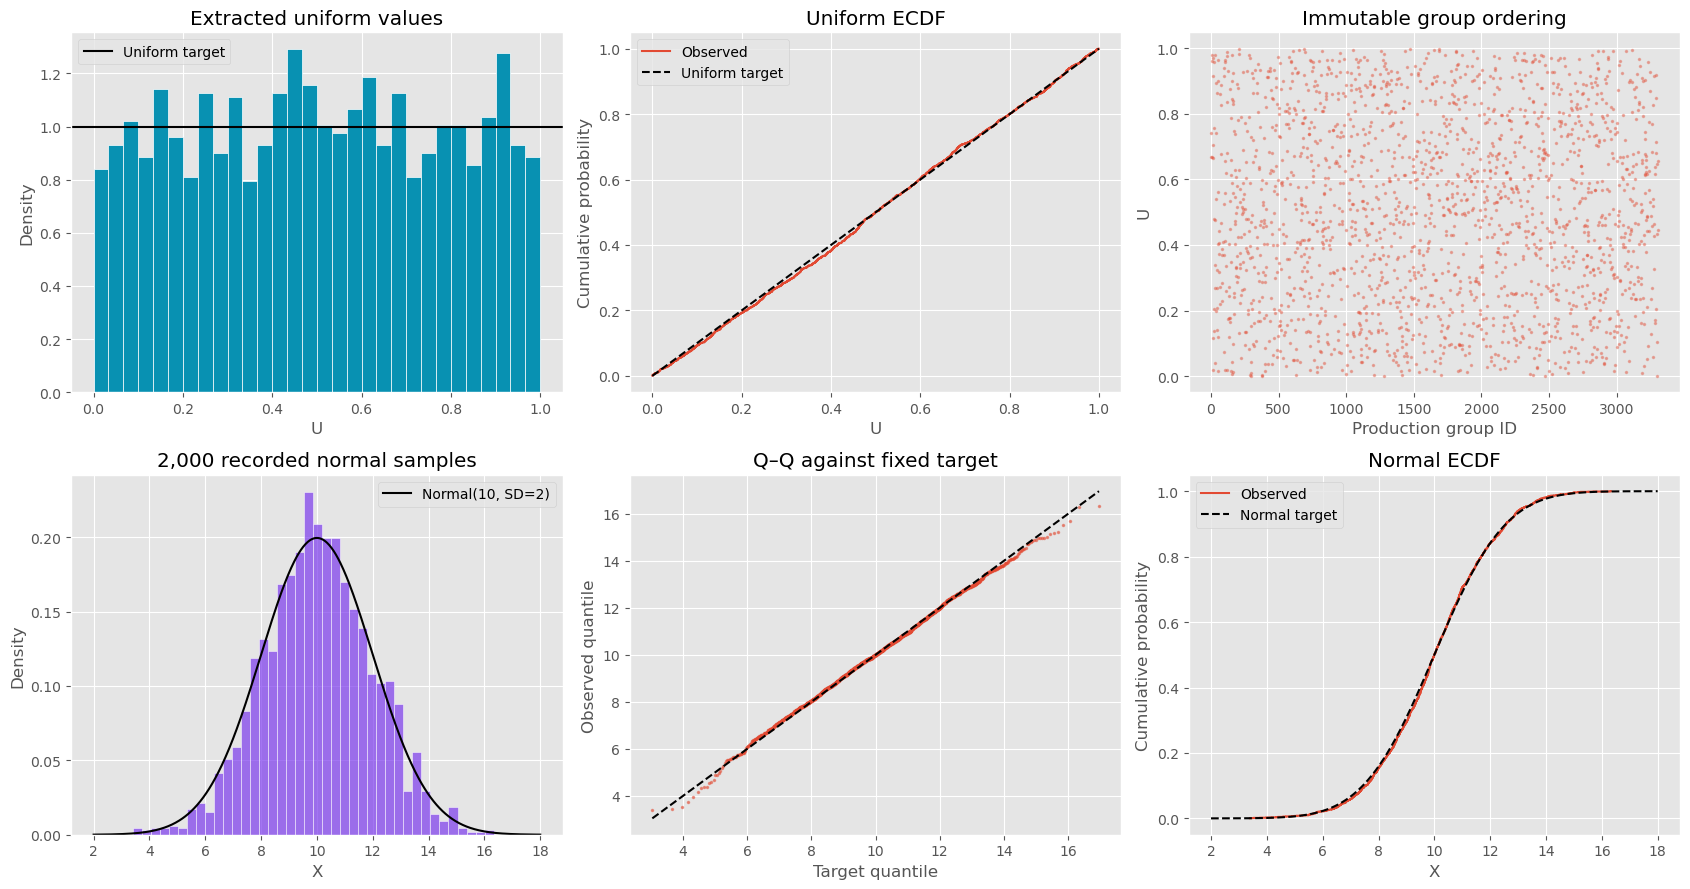

In [4]:
if len(samples):
    x = samples.X.to_numpy(dtype=float)
    u = samples.U.to_numpy(dtype=float)
    count = len(x)
    summary = pd.DataFrame({
        'statistic': ['count', 'mean', 'standard deviation (ddof=1)', 'minimum', 'maximum'],
        'observed': [count, x.mean(), x.std(ddof=1) if count > 1 else np.nan, x.min(), x.max()],
        'continuous target': [np.nan, 10, 2, -np.inf, np.inf],
    })
    display(summary)
    probs = np.array([0.001, 0.01, 0.025, 0.1, 0.25, 0.5, 0.75, 0.9, 0.975, 0.99, 0.999])
    quantiles = pd.DataFrame({'probability': probs, 'observed': np.quantile(x, probs),
                              'continuous target': stats.norm.ppf(probs, loc=10, scale=2)})
    display(quantiles)
    uniform_ks = stats.kstest(u, 'uniform')
    normal_ks = stats.kstest(x, 'norm', args=(10, 2))
    print('Uniform KS (continuous iid reference):', uniform_ks)
    print('Normal KS (continuous iid reference):', normal_ks)
    if count > 2:
        print('Lag-one correlation of U in group-ID order:', np.corrcoef(u[:-1], u[1:])[0, 1])
    block = pd.DataFrame({'block': np.arange(count) // 200, 'U': u, 'X': x})
    display(block.groupby('block').agg(count=('X', 'size'), mean_U=('U', 'mean'),
                                      mean_X=('X', 'mean'), std_X=('X', 'std')))

    fig, axes = plt.subplots(2, 3, figsize=(17, 9))
    axes[0, 0].hist(u, bins=np.linspace(0, 1, 31), density=True, color='#0891b2', edgecolor='white')
    axes[0, 0].axhline(1, color='black', label='Uniform target')
    axes[0, 0].set(title='Extracted uniform values', xlabel='U', ylabel='Density')
    axes[0, 0].legend()
    empirical = np.arange(1, count + 1) / count
    axes[0, 1].step(np.sort(u), empirical, where='post', label='Observed')
    axes[0, 1].plot([0, 1], [0, 1], 'k--', label='Uniform target')
    axes[0, 1].set(title='Uniform ECDF', xlabel='U', ylabel='Cumulative probability')
    axes[0, 1].legend()
    axes[0, 2].plot(samples.group_id, u, '.', alpha=0.35, markersize=3)
    axes[0, 2].set(title='Immutable group ordering', xlabel='Production group ID', ylabel='U')
    grid = np.linspace(min(2, x.min()), max(18, x.max()), 600)
    axes[1, 0].hist(x, bins=40, density=True, color='#7c3aed', edgecolor='white', alpha=0.7)
    axes[1, 0].plot(grid, stats.norm.pdf(grid, loc=10, scale=2), 'k-', label='Normal(10, SD=2)')
    axes[1, 0].set(title=f'{count:,} recorded normal samples', xlabel='X', ylabel='Density')
    axes[1, 0].legend()
    theoretical = stats.norm.ppf((np.arange(count) + 0.5) / count, loc=10, scale=2)
    axes[1, 1].plot(theoretical, np.sort(x), '.', alpha=0.5, markersize=3)
    endpoints = [min(theoretical.min(), x.min()), max(theoretical.max(), x.max())]
    axes[1, 1].plot(endpoints, endpoints, 'k--')
    axes[1, 1].set(title='Q–Q against fixed target', xlabel='Target quantile', ylabel='Observed quantile')
    axes[1, 2].step(np.sort(x), empirical, where='post', label='Observed')
    axes[1, 2].plot(grid, stats.norm.cdf(grid, loc=10, scale=2), 'k--', label='Normal target')
    axes[1, 2].set(title='Normal ECDF', xlabel='X', ylabel='Cumulative probability')
    axes[1, 2].legend()
    fig.tight_layout()
    fig.savefig(EXPORTS / 'permutation_normal_diagnostics.png', dpi=160, bbox_inches='tight')
    fig.savefig(EXPORTS / 'permutation_normal_diagnostics.svg', bbox_inches='tight')
    plt.show()
    summary.to_csv(EXPORTS / 'summary.csv', index=False)
    quantiles.to_csv(EXPORTS / 'quantiles.csv', index=False)
else:
    print('No eligible production samples: no distribution plots or numerical claims generated.')

## Interpretation and audit limits

One accepted group costs ten terminal calls, plus any HTTP retries. Discarded
groups and the pilot increase total cost. No value from the pilot is reused for
production, no tied group is repaired, and each selected group yields exactly
one normal sample. Invalid-response rejection preserves the ordering argument
only when validity is applied identically to identically distributed calls.

The ten-position permutation retains more information than the rank of just one
answer: it has $10!$, rather than ten, possible values. Nevertheless its quality
depends on the upstream model calls. The notebook records returned model and
fingerprint summaries but cannot prove provider-side independence or exclude
hidden caching. Repeated outputs alone neither establish nor disprove caching.
Multiple returned fingerprints also do not, by themselves, establish a failure of
exchangeability: the same routing mixture could apply independently at every
position. The position-specific proportions and homogeneous/mixed-group acceptance
tables inspect routing provenance; they neither prove identical output
distributions nor repair a difference. Temporal routing changes can matter even
when aggregate proportions look similar. Missing fingerprints are not treated as
evidence that requests used the same backend.

The CSV files in `llm_randomness/derived/permutation/` contain all raw integer calls,
all group decisions and intermediate arithmetic, and selected normal samples.
The original `responses.jsonl` and `attempts.jsonl` remain the authoritative call
and retry audit. A final complete report requires 2,000 eligible production
samples and the collector's completed, hash-verified snapshot.